# Pricing and Hedging an Up-and-Out Barrier Call

An up-and-out call pays $\max(S_T - K, 0)$ unless the stock touches a barrier $H$ above the
spot before expiry, in which case it is worthless. This notebook prices one under geometric
Brownian motion five ways: closed form, Monte Carlo with daily barrier checks, Monte Carlo
with a Brownian-bridge correction, a binomial tree, and the closed form with a continuity
correction. It then looks at the Greeks and at what happens when you try to delta-hedge one.

All pricing code lives in the `barrier_pricing` package (`src/barrier_pricing/`), which has
its own test suite; this notebook only calls it.

## Summary


- **Closed form.** With a continuously monitored barrier the up-and-out call is worth
  **3.333**, 68% less than the vanilla call (10.451).
- **Daily vs continuous monitoring.** Checking the barrier only at the daily close raises the
  price to about **3.55–3.57**. That is not simulation error: for contracts monitored at the
  daily close, it is the correct price. The Broadie–Glasserman–Kou shift reproduces it from
  the closed form (3.566), and works in reverse too.
- **Brownian-bridge Monte Carlo** removes the monitoring error exactly: 12 monthly steps give
  3.332 ± 0.029 (95% CI) in about 20 ms.
- **Variance reduction.** Antithetic pairs cut the variance by 30% once the standard error is
  computed on the pairs. The vanilla-call control variate removes a further 13%.
- **Binomial tree.** Biased up by 0.21 on average, and its error swings with a standard
  deviation of 0.13 as the number of steps changes. The BGK shift removes most of the bias,
  not the swings.
- **Hedging.** Daily delta hedging leaves a P&L standard deviation of 43% of the premium for
  the barrier option, against 4% for the vanilla call. 98% of the worst 1% of outcomes come
  from paths that got within 5% of the barrier.


In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from barrier_pricing import (
    MCResult,
    bgk_barrier,
    bs_call,
    bs_call_delta,
    crr_uoc,
    delta_hedge_pnl,
    price_barrier_mc,
    simulate_paths,
    uoc_call,
    uoc_delta,
    uoc_gamma,
)

S0, K, H = 100.0, 100.0, 130.0  # spot, strike, up-and-out barrier
r, sigma, T = 0.05, 0.20, 1.0  # risk-free rate, volatility, maturity (years)
STEPS = 252  # one barrier check per trading day
DT = T / STEPS
N_PATHS = 100_000

FIG_DIR = Path.cwd().parent / "figures"  # notebooks/ is the working directory
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def mc(**overrides):
    """Monte Carlo price of the base-case contract; keyword arguments override the defaults."""
    args = dict(S0=S0, K=K, H=H, r=r, sigma=sigma, T=T, steps=STEPS, n_paths=N_PATHS, rng=42)
    return price_barrier_mc(**{**args, **overrides})

## 1. Setup

Under the risk-neutral measure the stock follows

$$dS_t = r S_t\,dt + \sigma S_t\,dW_t,
\qquad S_{t+\Delta t} = S_t \exp\!\left[\left(r - \tfrac12\sigma^2\right)\Delta t
+ \sigma\sqrt{\Delta t}\,Z\right],\quad Z \sim \mathcal N(0,1),$$

which is exact on any time grid. The up-and-out call pays

$$V_T = \max(S_T - K, 0)\cdot \mathbf 1\Big\{\max_{t \le T} S_t < H\Big\}.$$

Base case: $S_0 = K = 100$, $H = 130$, $r = 5\%$, $\sigma = 20\%$, $T = 1$ year.

## 2. Closed-form benchmark

With a **continuously** monitored barrier the price has a closed form (Haug 2007; for
$K < H$ it is $A - B + C - D$, four Black-Scholes-like terms built from the reflection
principle). The knockout makes the option far cheaper than the vanilla call: the paths on
which the vanilla call pays the most are exactly the ones most likely to hit the barrier.

In [2]:
price_cont = uoc_call(S0, K, H, r, sigma, T)
price_vanilla = bs_call(S0, K, r, sigma, T)

print(f"Up-and-out call, continuous barrier: {price_cont:.4f}")
print(f"Vanilla call (Black-Scholes):        {price_vanilla:.4f}")
print(f"Knockout discount:                   {1 - price_cont / price_vanilla:.1%}")

Up-and-out call, continuous barrier: 3.3329
Vanilla call (Black-Scholes):        10.4506
Knockout discount:                   68.1%


## 3. Monte Carlo with daily barrier checks

Each path is checked against the barrier once per trading day. The pricer never stores whole
paths: it steps forward in time keeping only each path's current price and whether it is
still alive, so memory grows with the number of paths, not paths × steps.

**Antithetic variates.** Every normal draw $Z$ is paired with $-Z$. The two payoffs of a pair
are negatively correlated, so their average has lower variance than two independent payoffs.
The pairs, not the individual paths, are the independent samples, so the standard error has
to be computed from the pair averages. Treating all paths as independent overstates the error
and hides the gain.

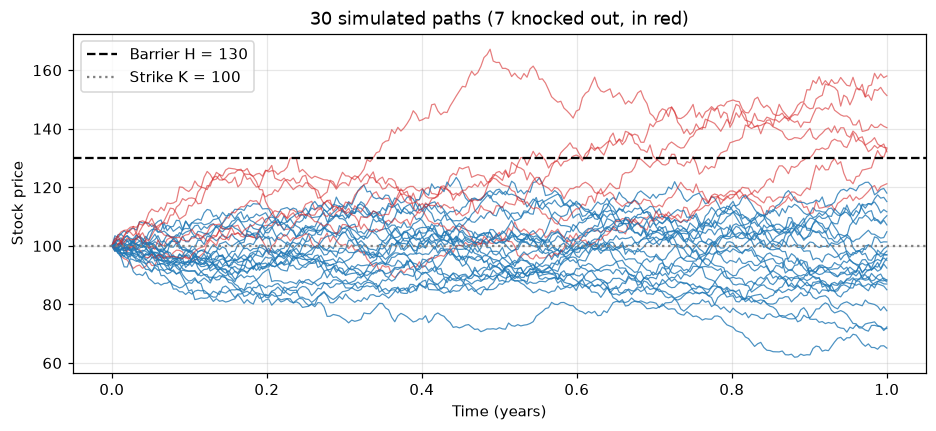

In [3]:
sample = simulate_paths(S0, r, sigma, T, STEPS, 30, rng=0)
t = np.linspace(0, T, STEPS + 1)
knocked = sample.max(axis=1) >= H

fig, ax = plt.subplots(figsize=(10, 4))
for path, out in zip(sample, knocked, strict=True):
    ax.plot(t, path, lw=0.8, color="tab:red" if out else "tab:blue", alpha=0.6 if out else 0.8)
ax.axhline(H, color="black", ls="--", lw=1.5, label=f"Barrier H = {H:.0f}")
ax.axhline(K, color="grey", ls=":", lw=1.5, label=f"Strike K = {K:.0f}")
ax.set(
    title=f"30 simulated paths ({knocked.sum()} knocked out, in red)",
    xlabel="Time (years)",
    ylabel="Stock price",
)
ax.legend(loc="upper left")
plt.show()

In [4]:
plain = mc(antithetic=False)
anti = mc()

print(f"{'Estimator':<12} {'Price':>8} {'SE':>8}   95% CI")
for name, res in [("Plain", plain), ("Antithetic", anti)]:
    lo, hi = res.ci95
    print(f"{name:<12} {res.price:>8.4f} {res.std_error:>8.4f}   [{lo:.4f}, {hi:.4f}]")

antithetic_cut = 1 - (anti.std_error / plain.std_error) ** 2
print(f"\nVariance reduction from antithetic pairs: {antithetic_cut:.0%}")
print(f"Gap to the continuous closed form: {anti.price - price_cont:+.4f}")

Estimator       Price       SE   95% CI
Plain          3.5680   0.0201   [3.5285, 3.6074]
Antithetic     3.5477   0.0169   [3.5146, 3.5809]

Variance reduction from antithetic pairs: 30%
Gap to the continuous closed form: +0.2149


## 4. Which price is right?

The daily-checked Monte Carlo price sits well above the closed form, and more paths will not
close the gap: a path can cross $H$ and come back between two daily checks, and the daily
contract does not count that as a knockout. The usual reading is that the simulation is
*biased*. But real barrier contracts are usually monitored at the **daily close**, not
continuously. For those contracts the daily-checked price is the correct one, and the
continuous closed form is the idealisation.

Broadie, Glasserman & Kou (1997) connect the two. An up barrier $H$ checked every
$\Delta t$ prices almost exactly like a continuously monitored barrier moved up to

$$H\,e^{\beta\sigma\sqrt{\Delta t}},
\qquad \beta = -\frac{\zeta(1/2)}{\sqrt{2\pi}} \approx 0.5826,$$

where $\zeta$ is the Riemann zeta function. That works in both directions:

- **Pricing a daily contract with the closed form:** shift $H$ *up* and use the continuous
  formula.
- **Getting the continuous price from a daily simulation:** shift $H$ *down* and simulate.

In [5]:
H_daily_equiv = bgk_barrier(H, sigma, DT, "discrete")  # continuous H that acts like daily checks
H_cont_equiv = bgk_barrier(H, sigma, DT, "continuous")  # daily H that acts like continuous
price_daily = uoc_call(S0, K, H_daily_equiv, r, sigma, T)
mc_shifted = mc(H=H_cont_equiv)

print("Daily-monitored contract")
print(f"  MC, daily checks at H = {H:.2f}            {anti.price:.4f}  (SE {anti.std_error:.4f})")
print(f"  Closed form at shifted H = {H_daily_equiv:.2f}     {price_daily:.4f}")
print("Continuously monitored contract")
print(f"  Closed form at H = {H:.2f}                 {price_cont:.4f}")
print(f"  MC, daily checks at shifted H = {H_cont_equiv:.2f} {mc_shifted.price:.4f}", end="")
print(f"  (SE {mc_shifted.std_error:.4f})")

Daily-monitored contract
  MC, daily checks at H = 130.00            3.5477  (SE 0.0169)
  Closed form at shifted H = 130.96     3.5660
Continuously monitored contract
  Closed form at H = 130.00                 3.3329
  MC, daily checks at shifted H = 129.05 3.3186  (SE 0.0164)


## 5. Brownian-bridge Monte Carlo

The BGK shift is an approximation. The bridge removes the monitoring error exactly. Given
the log-prices $x_i$ and $x_{i+1}$ at the ends of a step, both below $h = \ln H$, the
probability that the path touched the barrier in between is known in closed form:

$$p_i = \exp\!\left(-\frac{2\,(h - x_i)(h - x_{i+1})}{\sigma^2 \Delta t}\right).$$

Instead of killing a path only when a simulated point lands above $H$, each path carries the
weight $\prod_i (1 - p_i)$, the probability that it survived the whole step-by-step journey.
The estimator is then unbiased for the **continuous** barrier at any number of steps, so a
coarse monthly grid is enough.

In [6]:
bridge = mc(method="bridge")
bridge_12 = mc(method="bridge", steps=12)

print(f"Closed form, continuous barrier   {price_cont:.4f}")
print(f"Bridge MC, 252 daily steps        {bridge.price:.4f}  (SE {bridge.std_error:.4f})")
print(f"Bridge MC, 12 monthly steps       {bridge_12.price:.4f}  (SE {bridge_12.std_error:.4f})")

Closed form, continuous barrier   3.3329
Bridge MC, 252 daily steps        3.3246  (SE 0.0160)
Bridge MC, 12 monthly steps       3.3319  (SE 0.0146)


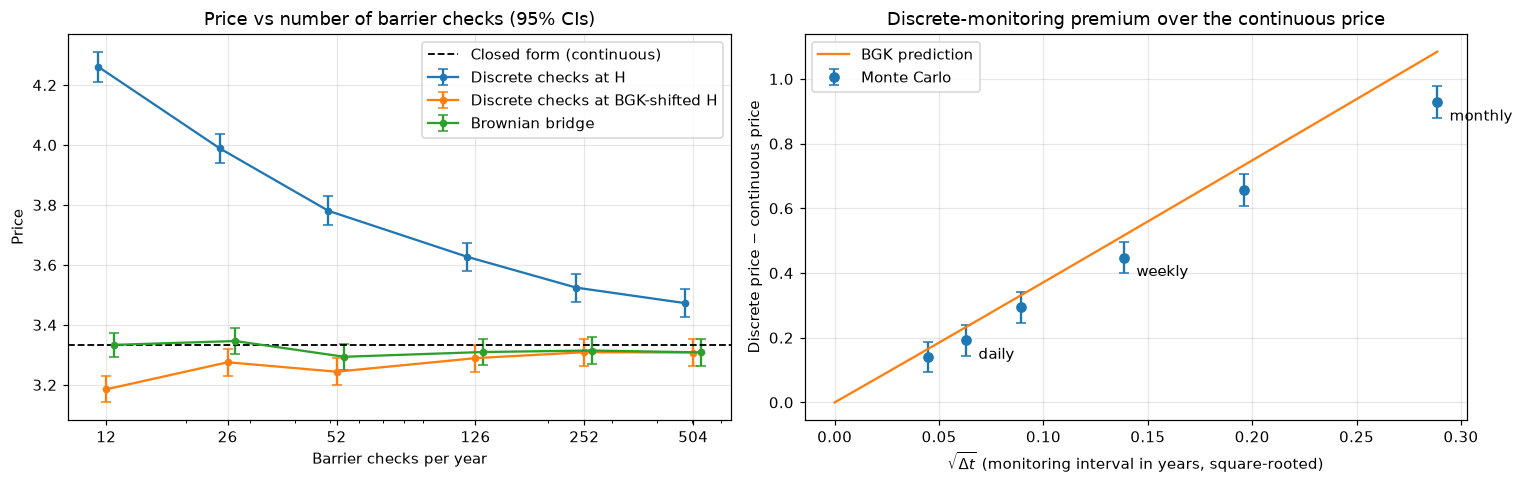

In [7]:
step_grid = np.array([12, 26, 52, 126, 252, 504])
labels = {
    "discrete": "Discrete checks at H",
    "shifted": "Discrete checks at BGK-shifted H",
    "bridge": "Brownian bridge",
}


def run(method, n):
    kw = dict(steps=n, n_paths=50_000)
    if method == "shifted":
        kw["H"] = bgk_barrier(H, sigma, T / n, "continuous")
    elif method == "bridge":
        kw["method"] = "bridge"
    return mc(**kw)


grid = {m: [run(m, n) for n in step_grid] for m in labels}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for i, (m, label) in enumerate(labels.items()):
    prices = [g.price for g in grid[m]]
    errors = [1.96 * g.std_error for g in grid[m]]
    x = step_grid * (1 + 0.05 * (i - 1))  # small offset so the error bars don't overlap
    ax1.errorbar(x, prices, yerr=errors, marker="o", ms=4, capsize=3, label=label)
ax1.axhline(price_cont, color="black", ls="--", lw=1.2, label="Closed form (continuous)")
ax1.set_xscale("log")
ax1.set_xticks(step_grid, [str(n) for n in step_grid])
ax1.set(
    title="Price vs number of barrier checks (95% CIs)",
    xlabel="Barrier checks per year",
    ylabel="Price",
)
ax1.legend()

sqrt_dt = np.sqrt(T / step_grid)
gap = [g.price - price_cont for g in grid["discrete"]]
gap_ci = [1.96 * g.std_error for g in grid["discrete"]]
fine = np.linspace(0, sqrt_dt.max(), 100)
bgk_gap = [uoc_call(S0, K, bgk_barrier(H, sigma, s**2, "discrete"), r, sigma, T) for s in fine]
ax2.errorbar(sqrt_dt, gap, yerr=gap_ci, fmt="o", capsize=3, label="Monte Carlo")
ax2.plot(fine, np.array(bgk_gap) - price_cont, label="BGK prediction")
for n, name in [(12, "monthly"), (52, "weekly"), (252, "daily")]:
    j = list(step_grid).index(n)
    ax2.annotate(name, (sqrt_dt[j], gap[j]), textcoords="offset points", xytext=(8, -12))
ax2.set(
    title="Discrete-monitoring premium over the continuous price",
    xlabel=r"$\sqrt{\Delta t}$ (monitoring interval in years, square-rooted)",
    ylabel="Discrete price − continuous price",
)
ax2.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "bias_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

Left: checking the barrier at $H$ itself converges to the continuous price only slowly. The
bridge sits on it at every grid size. The BGK-shifted barrier is close once the checks are
weekly or more frequent, but undershoots with monthly checks. Right: the gap between a
discretely monitored contract and the continuous one grows like $\sqrt{\Delta t}$. The BGK
formula predicts it well for frequent monitoring and overstates it for sparse monitoring,
as you would expect from an asymptotic correction.

## 6. Control variates

The vanilla call payoff is available on every path and has a known mean (Black-Scholes), so
it can serve as a control variate:

$$\hat V_{CV} = \hat V - c^{\star}\left(\hat C^{MC} - C^{BS}\right),
\qquad c^{\star} =\frac{\operatorname{Cov}(V, C)}{\operatorname{Var}(C)}.$$

The variance falls by a factor $1 - \rho^2$, where $\rho$ is the correlation between the
two payoffs.

In [8]:
cv = mc(control_variate=True)
cv_cut = 1 - (cv.std_error / anti.std_error) ** 2
knocked_share = (simulate_paths(S0, r, sigma, T, STEPS, 20_000, rng=1).max(axis=1) >= H).mean()

print(f"Antithetic                    {anti.price:.4f}  (SE {anti.std_error:.5f})")
print(f"Antithetic + control variate  {cv.price:.4f}  (SE {cv.std_error:.5f})")
print(f"Variance reduction: {cv_cut:.1%}  ->  implied payoff correlation {np.sqrt(cv_cut):.2f}")
print(f"Share of paths knocked out: {knocked_share:.0%}")

Antithetic                    3.5477  (SE 0.01691)
Antithetic + control variate  3.5509  (SE 0.01572)
Variance reduction: 13.5%  ->  implied payoff correlation 0.37
Share of paths knocked out: 22%


The gain is modest, and that is expected rather than a bug. On roughly one path in five the
barrier option is knocked out and pays zero. These are the paths where the stock rallied,
so they are also the paths where the vanilla call pays the most. A control that is largest
exactly where the target is zero is a weak control. A stronger control would be one that
also dies at the barrier.

## 7. Binomial tree

A Cox-Ross-Rubinstein tree with $u = e^{\sigma\sqrt{\Delta t}}$, $d = 1/u$ and
$p = (e^{r\Delta t} - d)/(u - d)$ handles the barrier by zeroing every node at or above $H$.
Two problems show up:

- **Bias:** the tree only checks the barrier at its time steps, so it inherits the same
  upward bias as daily-checked Monte Carlo.
- **Oscillation:** the barrier almost never sits exactly on a row of nodes. As $N$ changes,
  the effective barrier (the first row of nodes above $H$) jumps around, so the price
  oscillates irregularly instead of converging smoothly.

Shifting the barrier down by the BGK correction removes most of the bias but not the
oscillation. Placing the barrier on a row of nodes (Boyle & Lau 1994) would fix that too.

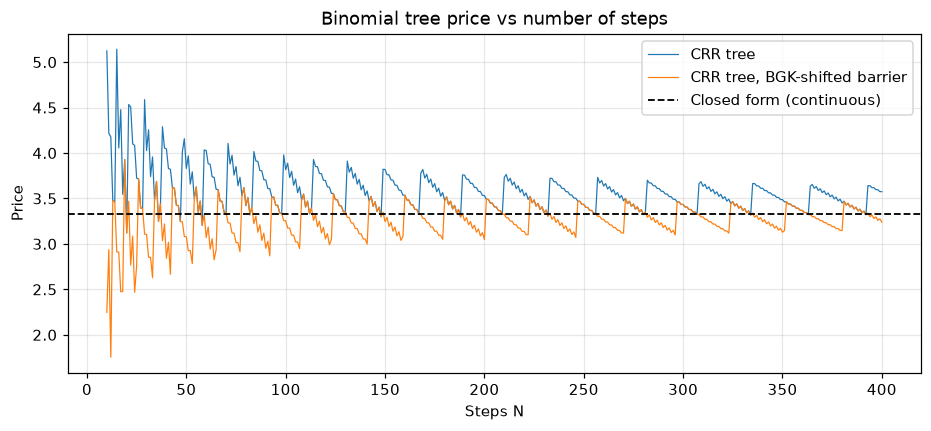

Over N = 100..400        mean error   std of error
  CRR                      +0.2050         0.1347
  CRR + BGK                -0.0468         0.1256


In [9]:
n_grid = np.arange(10, 401)
tree_plain = np.array([crr_uoc(S0, K, H, r, sigma, T, n) for n in n_grid])
tree_bgk = np.array([crr_uoc(S0, K, H, r, sigma, T, n, bgk=True) for n in n_grid])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(n_grid, tree_plain, lw=0.8, label="CRR tree")
ax.plot(n_grid, tree_bgk, lw=0.8, label="CRR tree, BGK-shifted barrier")
ax.axhline(price_cont, color="black", ls="--", lw=1.2, label="Closed form (continuous)")
ax.set(title="Binomial tree price vs number of steps", xlabel="Steps N", ylabel="Price")
ax.legend()
plt.show()

avg = n_grid >= 100
print("Over N = 100..400        mean error   std of error")
for name, prices in [("CRR", tree_plain), ("CRR + BGK", tree_bgk)]:
    err = prices[avg] - price_cont
    print(f"  {name:<20} {err.mean():>+11.4f} {err.std():>14.4f}")

## 8. Greeks

Delta and gamma come from central finite differences of the closed form. The interesting
part is how differently they behave from a vanilla call's.

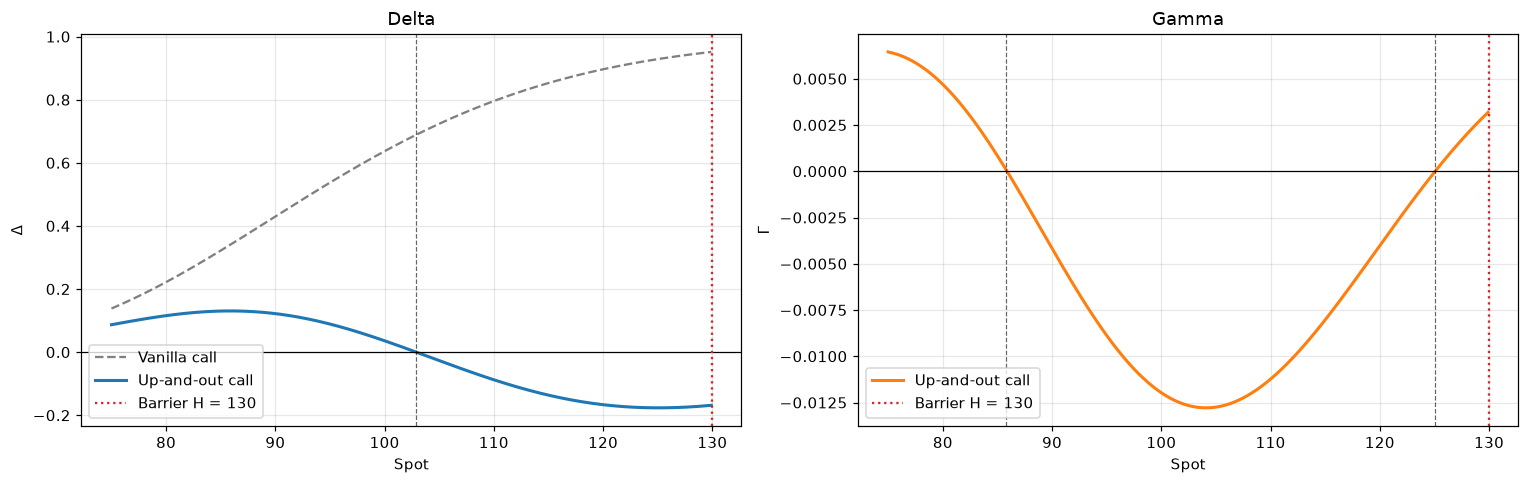

At S0 = 100: delta +0.0360, gamma -0.01197
Delta changes sign at S ≈ 102.9
Gamma changes sign at S ≈ 85.8, 125.1
Delta just below the barrier (S = 129.9): -0.169


In [10]:
S_grid = np.linspace(75, 129.9, 1000)
delta = uoc_delta(S_grid, K, H, r, sigma, T)
gamma = uoc_gamma(S_grid, K, H, r, sigma, T)


def sign_changes(x, y):
    """Points of x where y changes sign."""
    return x[np.flatnonzero(np.diff(np.sign(y)))]


delta_flips = sign_changes(S_grid, delta)
gamma_flips = sign_changes(S_grid, gamma)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(S_grid, bs_call_delta(S_grid, K, r, sigma, T), "--", color="grey", label="Vanilla call")
ax1.plot(S_grid, delta, lw=2, label="Up-and-out call")
ax2.plot(S_grid, gamma, lw=2, color="tab:orange", label="Up-and-out call")
for ax, flips in [(ax1, delta_flips), (ax2, gamma_flips)]:
    ax.axhline(0, color="black", lw=0.8)
    ax.axvline(H, color="tab:red", ls=":", lw=1.5, label=f"Barrier H = {H:.0f}")
    for s in flips:
        ax.axvline(s, color="black", ls="--", lw=0.8, alpha=0.6)
ax1.set(title="Delta", xlabel="Spot", ylabel=r"$\Delta$")
ax2.set(title="Gamma", xlabel="Spot", ylabel=r"$\Gamma$")
ax1.legend(loc="lower left")
ax2.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "greeks.png", dpi=150, bbox_inches="tight")
plt.show()

print(
    f"At S0 = {S0:.0f}: delta {uoc_delta(S0, K, H, r, sigma, T):+.4f}, "
    f"gamma {uoc_gamma(S0, K, H, r, sigma, T):+.5f}"
)
print("Delta changes sign at S ≈", ", ".join(f"{s:.1f}" for s in delta_flips))
print("Gamma changes sign at S ≈", ", ".join(f"{s:.1f}" for s in gamma_flips))
print(f"Delta just below the barrier (S = {S_grid[-1]}): {delta[-1]:+.3f}")


With a year to go, the barrier option's Greeks already look nothing like a vanilla call's:

- **Delta** is positive only below $S \approx 103$. Above that, a rise in the stock adds more
  knockout risk than intrinsic value, so the option loses value. Just below the barrier,
  delta is about $-0.17$, against $+0.95$ for the vanilla call.
- **Gamma** has three regimes. It is positive below $S \approx 86$, where the barrier is far
  away and the option behaves like a vanilla call. It is negative between about 86 and 125,
  where the value curve is a hump. It turns positive again within about 4% of the barrier,
  where the value bends down to zero.

These profiles are for one year to expiry. Near expiry they become much more extreme close
to the barrier, because the payoff drops from about 30 to 0 at $H$. With a week left, delta at
$S = 128$ is about $-4$; with a day left, at $S = 129.5$, it is about $-9$. That is what breaks
the hedge in the next section.


## 9. Delta hedging

To see what those Greeks mean in practice, sell one option at its model price and hedge
it with the stock, rebalancing every $k$ trading days. Cash earns the risk-free rate.
The barrier option is the **daily-monitored** contract: it is knocked out at the first daily
close at or above $H$, whatever the rebalancing frequency, and its price and delta come from
the closed form at the BGK-shifted barrier (Section 4). On a knockout the hedge is unwound at
that day's price. The same 20,000 paths are used for every frequency, so the comparisons are
not blurred by sampling noise. The vanilla call gets exactly the same treatment.

In [11]:
hedge_paths = simulate_paths(S0, r, sigma, T, STEPS, 20_000, rng=2024)
premium = {"vanilla": price_vanilla, "uoc": price_daily}
freqs = [21, 10, 5, 2, 1]
pnl = {
    opt: {k: delta_hedge_pnl(opt, hedge_paths, K, H, r, sigma, T, rebalance_every=k) for k in freqs}
    for opt in ("vanilla", "uoc")
}

print("Hedging P&L as a fraction of the premium received")
print(f"{'Rebalance every':<17}{'Vanilla std':>12}{'Barrier std':>13}{'Barrier 1% quantile':>21}")
for k in freqs:
    v = pnl["vanilla"][k] / premium["vanilla"]
    u = pnl["uoc"][k] / premium["uoc"]
    print(f"{k:>3} day(s)       {v.std():>12.3f}{u.std():>13.3f}{np.quantile(u, 0.01):>21.2f}")

Hedging P&L as a fraction of the premium received
Rebalance every   Vanilla std  Barrier std  Barrier 1% quantile
 21 day(s)              0.185        1.112                -3.92
 10 day(s)              0.128        0.871                -2.98
  5 day(s)              0.091        0.682                -2.15
  2 day(s)              0.058        0.524                -1.51
  1 day(s)              0.041        0.433                -1.10


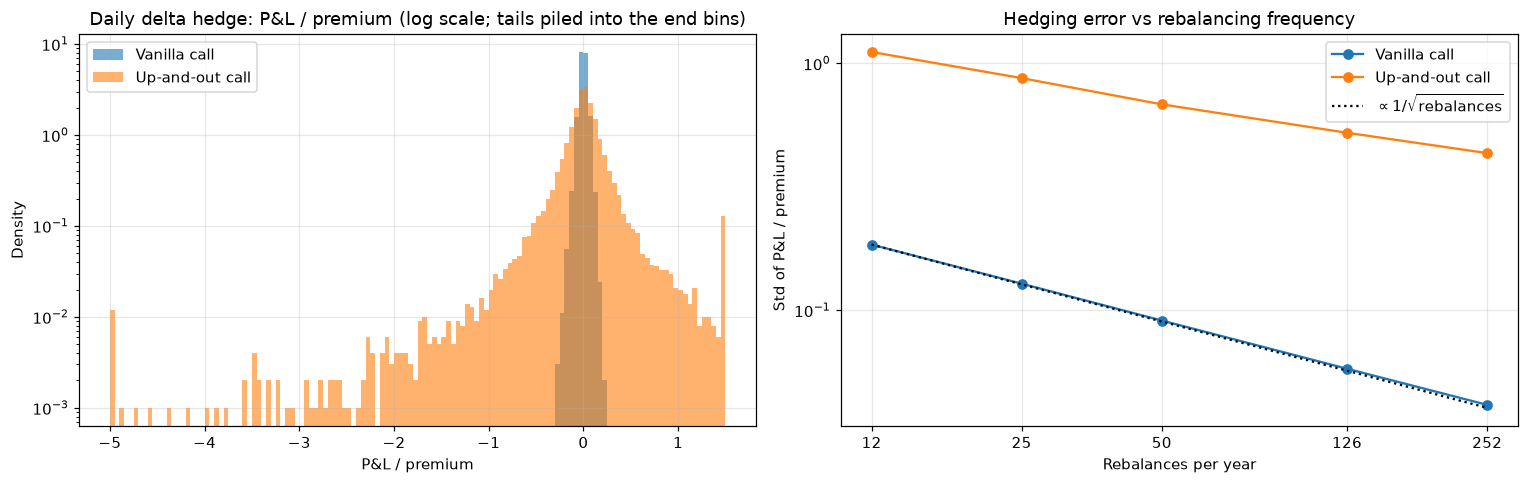

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.linspace(-5, 1.5, 131)
for opt, label in [("vanilla", "Vanilla call"), ("uoc", "Up-and-out call")]:
    rel = np.clip(pnl[opt][1] / premium[opt], bins[0], bins[-1])
    ax1.hist(rel, bins=bins, density=True, alpha=0.6, label=label)
ax1.set_yscale("log")
ax1.set(
    title="Daily delta hedge: P&L / premium (log scale; tails piled into the end bins)",
    xlabel="P&L / premium",
    ylabel="Density",
)
ax1.legend()

n_rebalances = np.array([STEPS / k for k in freqs])
for opt, label in [("vanilla", "Vanilla call"), ("uoc", "Up-and-out call")]:
    stds = [(pnl[opt][k] / premium[opt]).std() for k in freqs]
    ax2.plot(n_rebalances, stds, "o-", label=label)
ref = (pnl["vanilla"][freqs[0]] / premium["vanilla"]).std() * np.sqrt(
    n_rebalances[0] / n_rebalances
)
ax2.plot(n_rebalances, ref, "k:", label=r"$\propto 1/\sqrt{\text{rebalances}}$")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.minorticks_off()
ax2.set_xticks(n_rebalances, [f"{n:.0f}" for n in n_rebalances])
ax2.set(
    title="Hedging error vs rebalancing frequency",
    xlabel="Rebalances per year",
    ylabel="Std of P&L / premium",
)
ax2.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "hedging_pnl.png", dpi=150, bbox_inches="tight")
plt.show()

Where do the barrier option's large losses come from? Group the paths by how close each one got to the barrier.

In [13]:
daily = pnl["uoc"][1] / premium["uoc"]
closeness = hedge_paths.max(axis=1) / H
buckets = [
    ("max below 0.90 H", 0.0, 0.90),
    ("max 0.90 H - 0.97 H", 0.90, 0.97),
    ("max 0.97 H - H", 0.97, 1.0),
    ("knocked out", 1.0, np.inf),
]
print(f"{'Path group':<22}{'Share':>7}{'Mean P&L':>10}{'Std P&L':>9}   (P&L / premium)")
for name, lo, hi in buckets:
    m = (closeness >= lo) & (closeness < hi)
    print(f"{name:<22}{m.mean():>7.1%}{daily[m].mean():>+10.3f}{daily[m].std():>9.3f}")

tail = daily <= np.quantile(daily, 0.01)
near = (closeness >= 0.95).mean()
print(f"\nPaths whose maximum came within 5% of H: {near:.0%} of all paths, ", end="")
print(f"{(closeness[tail] >= 0.95).mean():.0%} of the worst 1% of P&L")

Path group              Share  Mean P&L  Std P&L   (P&L / premium)
max below 0.90 H        53.2%    -0.000    0.121
max 0.90 H - 0.97 H     18.8%    -0.016    0.334
max 0.97 H - H           6.0%    -0.141    1.118
knocked out             21.9%    +0.080    0.607

Paths whose maximum came within 5% of H: 33% of all paths, 98% of the worst 1% of P&L



- **Vanilla call.** The hedging error falls almost exactly like
  $1/\sqrt{\text{rebalances}}$: rebalancing daily instead of monthly cuts it by a factor of 4.5
  ($\sqrt{21} \approx 4.6$).
- **Barrier option.** The same change cuts the error only by a factor of 2.6. Even with daily
  rebalancing the P&L standard deviation is 43% of the premium, against 4% for the vanilla
  call, and the worst 1% of outcomes lose more than the whole premium.
- **Where the losses are.** Paths that came within 5% of the barrier are a third of all
  paths but produce 98% of the worst 1% of outcomes. Paths that got within 3% of $H$ and
  survived have a P&L spread about nine times that of paths that stayed below $0.9H$.
- **Why.** Close to the barrier and close to expiry, a one-day move changes the required
  hedge by several shares per option (Section 8), and a hedge rebalanced once a day cannot
  keep up. This is why barrier options are rarely delta-hedged naively. In practice, desks
  shift the barrier in their risk models or hedge statically with vanilla options.


## 10. Summary table

The error column compares each method with the closed-form reference for the contract it
targets: the continuous closed form, or the BGK-shifted closed form for the daily contract.
The daily reference is itself an approximation. Runtimes depend on the machine; for the
trees they are for a single tree with $N = 252$.

In [14]:
def timed(fn):
    start = time.perf_counter()
    out = fn()
    return out, 1000 * (time.perf_counter() - start)


reference = {"continuous": price_cont, "daily": price_daily}
methods = [
    ("Closed form", "continuous", lambda: uoc_call(S0, K, H, r, sigma, T)),
    ("Closed form, BGK-shifted H", "daily", lambda: uoc_call(S0, K, H_daily_equiv, r, sigma, T)),
    ("MC daily, plain", "daily", lambda: mc(antithetic=False)),
    ("MC daily, antithetic", "daily", lambda: mc()),
    ("MC daily, antithetic + control", "daily", lambda: mc(control_variate=True)),
    ("MC daily, BGK-shifted H", "continuous", lambda: mc(H=H_cont_equiv)),
    ("Bridge MC, 252 steps", "continuous", lambda: mc(method="bridge")),
    ("Bridge MC, 12 steps", "continuous", lambda: mc(method="bridge", steps=12)),
]

print(f"{'Method':<36}{'Target':<12}{'Price':>8}{'SE':>8}{'Error':>9}{'Time (ms)':>11}")
print("-" * 84)
for name, target, fn in methods:
    out, ms = timed(fn)
    price, se = (out.price, f"{out.std_error:.4f}") if isinstance(out, MCResult) else (out, "")
    err = price - reference[target]
    print(f"{name:<36}{target:<12}{price:>8.4f}{se:>8}{err:>+9.4f}{ms:>11.1f}")
for name, prices, bgk in [
    ("CRR tree (mean N = 100-400)", tree_plain, False),
    ("CRR tree, BGK (mean N = 100-400)", tree_bgk, True),
]:
    _, ms = timed(lambda b=bgk: crr_uoc(S0, K, H, r, sigma, T, 252, bgk=b))
    price = prices[avg].mean()
    print(f"{name:<36}{'continuous':<12}{price:>8.4f}{'':>8}{price - price_cont:>+9.4f}{ms:>11.1f}")

Method                              Target         Price      SE    Error  Time (ms)
------------------------------------------------------------------------------------
Closed form                         continuous    3.3329          +0.0000        0.6
Closed form, BGK-shifted H          daily         3.5660          +0.0000        0.5


MC daily, plain                     daily         3.5680  0.0201  +0.0019      266.5
MC daily, antithetic                daily         3.5477  0.0169  -0.0183      160.9


MC daily, antithetic + control      daily         3.5509  0.0157  -0.0151      156.1
MC daily, BGK-shifted H             continuous    3.3186  0.0164  -0.0143      159.2


Bridge MC, 252 steps                continuous    3.3246  0.0160  -0.0082      632.8
Bridge MC, 12 steps                 continuous    3.3319  0.0146  -0.0010       17.8
CRR tree (mean N = 100-400)         continuous    3.5379          +0.2050        4.3
CRR tree, BGK (mean N = 100-400)    continuous    3.2861          -0.0468        3.8


## 11. Limitations

- **Constant volatility.** Barrier options are sensitive to the volatility smile: what
  matters most is the volatility at spot levels near the barrier, not at the money. Local or
  stochastic volatility models price them noticeably differently.
- **No jumps.** A jump can carry the stock straight through the barrier, which both changes
  the price and makes the hedge fail more often than continuous diffusion suggests.
- **Frictionless hedging.** The hedging study has no transaction costs and trades at the
  close. Near the barrier the hedge trades large quantities at exactly the worst time.
  Desks use barrier shifts and static hedges instead.
- **Approximate corrections.** The BGK shift is an asymptotic result. It is less accurate
  when the barrier is very close to spot or checks are very sparse. The tree's oscillation
  remains after the shift.

## References

- Broadie, M., Glasserman, P. & Kou, S. (1997). A continuity correction for discrete barrier
  options. *Mathematical Finance*, 7(4), 325–349.
- Boyle, P. & Lau, S. H. (1994). Bumping up against the barrier with the binomial method.
  *Journal of Derivatives*, 1(4), 6–14.
- Glasserman, P. (2004). *Monte Carlo Methods in Financial Engineering*. Springer.
- Haug, E. G. (2007). *The Complete Guide to Option Pricing Formulas* (2nd ed.). McGraw-Hill.
- Hull, J. C. *Options, Futures, and Other Derivatives*. Pearson.